# Port Hawkesbury before the data centre: a first look at the baseline

**Status: prototype, 18 November 2026. Two series only. Nothing here is a finding.**

A data centre campus was announced for Point Tupper, Nova Scotia, on 16 October 2026.
The site is in Richmond County. The town next to it, Port Hawkesbury, is in Inverness County.
This notebook starts the "before" record for a long-term study of what the project does
to the town's economy.

It does three things:

1. It pulls two public Statistics Canada series and keeps a small cached copy.
2. It plots Port Hawkesbury beside a first, unverified list of comparison towns.
3. It measures how much these series move in a normal year.

**Sources.** Statistics Canada tables 17-10-0155-01, 17-10-0152-01 and 14-10-0323-01,
through the Web Data Service. Every cached row keeps its table, coordinate and vector number.
Adapted from Statistics Canada data under the Statistics Canada Open Licence.
This does not constitute an endorsement by Statistics Canada of this product.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import statcan

REFRESH = False  # True: fetch again from Statistics Canada. False: use the cached files.
DATA = Path("data")
DATA.mkdir(exist_ok=True)

ANNOUNCED = pd.Timestamp("2026-10-16")  # EverWind's announcement (company release)
TOWN = "1215002"  # Port Hawkesbury

towns = pd.read_csv("towns.csv", dtype={"csduid": str})
towns.groupby("role").size().rename("units")

role
donor        38
host          1
neighbour     4
town          1
Name: units, dtype: int64

## Series 1: population of each town, 1 July, 2001 to 2025

Table 17-10-0155-01, *Population estimates, July 1, by census subdivision, 2021 boundaries*.
A census subdivision is a municipality. The table has one value per town per year.

These are **estimates, not counts**. Statistics Canada starts from the census and moves
each town forward with tax-file data. The years 2022 to 2025 are not final, and all years
after 2021 will be revised when the 2026 Census counts arrive (first release: 10 February 2027).

In [2]:
def cached(name: str, build) -> pd.DataFrame:
    """Read a cached CSV, or build it from the API and save it."""
    path = DATA / name
    if REFRESH or not path.exists():
        build().to_csv(path, index=False)
    return pd.read_csv(path, dtype={"code": str})


# The baseline window is fixed here, by date. A refresh may bring newer periods from the
# API; they are dropped, so "before" keeps the same meaning. To extend the record on
# purpose, change these dates.
POP_FIRST, POP_LAST = "2001-07-01", "2025-07-01"  # 25 yearly values
EI_FIRST, EI_LAST = "2001-01-01", "2026-09-01"  # 309 monthly values; the announcement was 16 Oct 2026


def window(data: pd.DataFrame, requested, first: str, last: str, periods: int) -> pd.DataFrame:
    """Keep the fixed baseline window and check that every requested series is complete in it."""
    data = data[data["ref_date"].between(first, last)]
    absent = set(requested) - set(data["coordinate"])
    assert not absent, f"requested series not returned: {sorted(absent)}"
    counts = data.groupby("coordinate")["ref_date"].nunique()
    assert len(data) == counts.sum(), "duplicate periods"
    assert (counts == periods).all(), f"incomplete series: {counts[counts != periods].to_dict()}"
    return data


def population_by_town() -> pd.DataFrame:
    members = statcan.geography_members(statcan.cube_metadata(17100155))
    members = members[members["code"].isin(towns["csduid"])]
    missing = set(towns["csduid"]) - set(members["code"])
    assert not missing, f"not in table 17-10-0155-01: {missing}"
    members["coordinate"] = members["member_id"].map(statcan.coordinate)
    data = statcan.fetch(17100155, list(members["coordinate"]), latest_n=40)
    data = window(data, members["coordinate"], POP_FIRST, POP_LAST, periods=25)
    return data.merge(members[["coordinate", "code", "statcan_name"]], on="coordinate")


pop = cached("population_csd_17100155.csv", population_by_town)
pop["year"] = pd.to_datetime(pop["ref_date"]).dt.year
pop = pop.merge(towns, left_on="code", right_on="csduid")
print(len(pop), "rows;", pop["code"].nunique(), "places;", pop["year"].min(), "to", pop["year"].max())
print("released by Statistics Canada:", pop["released"].max(), "| fetched:", pop["fetched_at"].max())

levels = pop.pivot(index="year", columns="name", values="value")
assert list(levels.index) == list(range(2001, 2026)) and not levels.isna().any().any()
levels[["Port Hawkesbury", "Richmond, Subd. A", "Inverness, Subd. C", "Mulgrave"]].loc[
    [2001, 2006, 2011, 2016, 2021, 2025]
]

1100 rows; 44 places; 2001 to 2025
released by Statistics Canada: 2026-01-14T08:30 | fetched: 2026-11-18T22:10:00-04:00


name,Port Hawkesbury,"Richmond, Subd. A","Inverness, Subd. C",Mulgrave
year,,,,
2001,3796.0,4168.0,3889.0,924.0
2006,3595.0,4124.0,3706.0,890.0
2011,3434.0,3984.0,3377.0,806.0
2016,3258.0,3809.0,3207.0,718.0
2021,3303.0,3848.0,3247.0,638.0
2025,3442.0,4305.0,3314.0,639.0


### Port Hawkesbury beside the candidate comparison towns

Each line is a town's population as an index (2001 = 100), so towns of different sizes
can share one chart. Grey lines are the candidate "donor" towns in `towns.csv`.
The list is a first draft and its notes are not yet checked against sources.

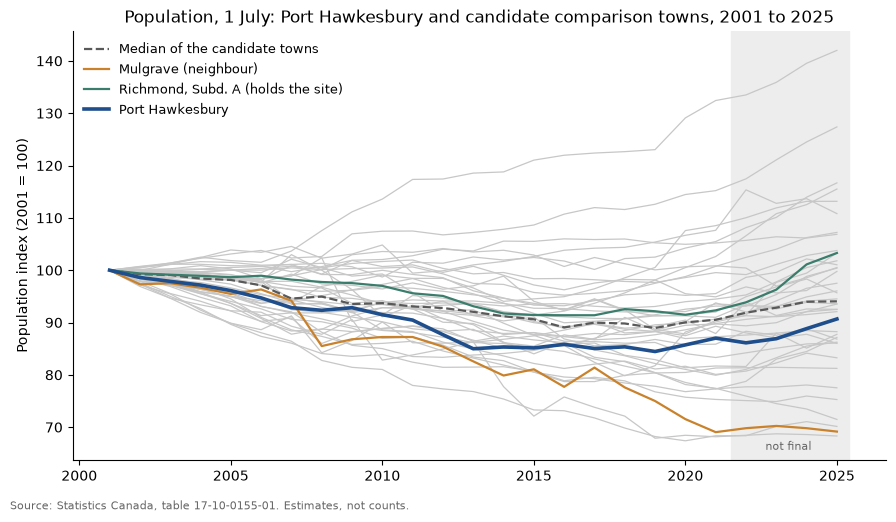

In [3]:
index = levels / levels.loc[2001] * 100
donors = towns.loc[towns["role"] == "donor", "name"]

fig, ax = plt.subplots(figsize=(9, 5.2))
for name in donors:
    ax.plot(index.index, index[name], color="0.78", linewidth=0.9)
ax.plot(index.index, index[donors].median(axis=1), color="0.35", linewidth=1.6,
        linestyle="--", label="Median of the candidate towns")
ax.plot(index.index, index["Mulgrave"], color="#c9822b", linewidth=1.6, label="Mulgrave (neighbour)")
ax.plot(index.index, index["Richmond, Subd. A"], color="#3a7d6b", linewidth=1.6,
        label="Richmond, Subd. A (holds the site)")
ax.plot(index.index, index["Port Hawkesbury"], color="#1f4e8c", linewidth=2.6, label="Port Hawkesbury")
ax.axvspan(2021.5, 2025.4, color="0.93", zorder=0)
ax.text(2023.4, ax.get_ylim()[0] + 2, "not final", ha="center", fontsize=8, color="0.4")
ax.set_ylabel("Population index (2001 = 100)")
ax.set_title("Population, 1 July: Port Hawkesbury and candidate comparison towns, 2001 to 2025")
ax.legend(frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, 0.01, "Source: Statistics Canada, table 17-10-0155-01. Estimates, not counts.",
         fontsize=8, color="0.4")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig("fig-population-index.png", dpi=160)
plt.show()

### Which towns moved like Port Hawkesbury?

A simple description, **not** a control design: the root-mean-square gap between each
town's index and Port Hawkesbury's, over 2001 to 2025. A small gap means the two
populations followed a similar path. It does not mean the two economies are alike.

In [4]:
gap = index[donors].sub(index["Port Hawkesbury"], axis=0)
closest = (
    (gap**2).mean().pow(0.5).rename("rms_gap_index_points").sort_values().round(1).to_frame()
    .join(levels.loc[2025].rename("population_2025").astype(int))
    .join(towns.set_index("name")["prov"])
)
closest.head(12)

,rms_gap_index_points,population_2025,prov
name,,,
Campbellton,2.3,7485,NB
Yarmouth,2.3,7129,NS
Queens (Liverpool),2.6,10997,NS
Stellarton,2.6,4251,NS
Trenton,2.9,2499,NS
Botwood,3.2,2884,NL
Shelburne,3.4,1797,NS
Marystown,3.4,5196,NL
Pictou,3.4,3307,NS


### How much does the series move in a normal year?

The project promises 215 permanent jobs across the campus and four wind farms
(a company figure, from the release of 16 October 2026). The forecast does not say how many more
people will live in the town, or when. The table below shows only how much the town's
population moves from year to year. Whether an effect can be seen will depend on how
closely a comparison follows the town before the project.

In [5]:
ph = levels["Port Hawkesbury"]
change = ph.diff().dropna()
summary = pd.Series(
    {
        "Population, 1 July 2025 (preliminary)": ph.loc[2025],
        "Average yearly change, 2001 to 2021": change.loc[:2021].mean().round(1),
        "Standard deviation of yearly change, 2001 to 2021": change.loc[:2021].std().round(1),
        "Largest yearly fall, 2001 to 2021": change.loc[:2021].min(),
        "Largest yearly rise, 2001 to 2021": change.loc[:2021].max(),
        "Change 2021 to 2025 (not final)": ph.loc[2025] - ph.loc[2021],
    }
)
summary.to_frame("Port Hawkesbury")

,Port Hawkesbury
"Population, 1 July 2025 (preliminary)",3442.0
"Average yearly change, 2001 to 2021",-24.6
"Standard deviation of yearly change, 2001 to 2021",43.5
"Largest yearly fall, 2001 to 2021",-106.0
"Largest yearly rise, 2001 to 2021",49.0
Change 2021 to 2025 (not final),139.0


## Series 2: Employment Insurance, monthly, by county

Table 14-10-0323-01, *Employment insurance beneficiaries by census division, monthly,
unadjusted for seasonality*. People who receive regular benefits, both sexes, 15 years and over.

This table is monthly, and its limit is geography: it stops at the county (census division).
(Table 14-10-0480-01 has monthly employment for a small labour area since late 2021; not used yet.)
Port Hawkesbury is one part of Inverness County, so a town effect is diluted in it.

To compare counties, the count is divided by the county's total population on 1 July
of the same year (table 17-10-0152-01). This is a rate per 1,000 residents of all ages,
not an unemployment rate.

Read it with care. The count follows the programme's rules as well as the job market.
In 2020 most claimants moved to emergency benefits, and in 2020-21 the entry rules were
relaxed, so the dip and the spike in those years are mostly policy. A falling count can
also mean that claims ran out, not that people found work.

2472 rows; 2001-01-01 to 2026-09-01 | released: 2026-11-18T08:30


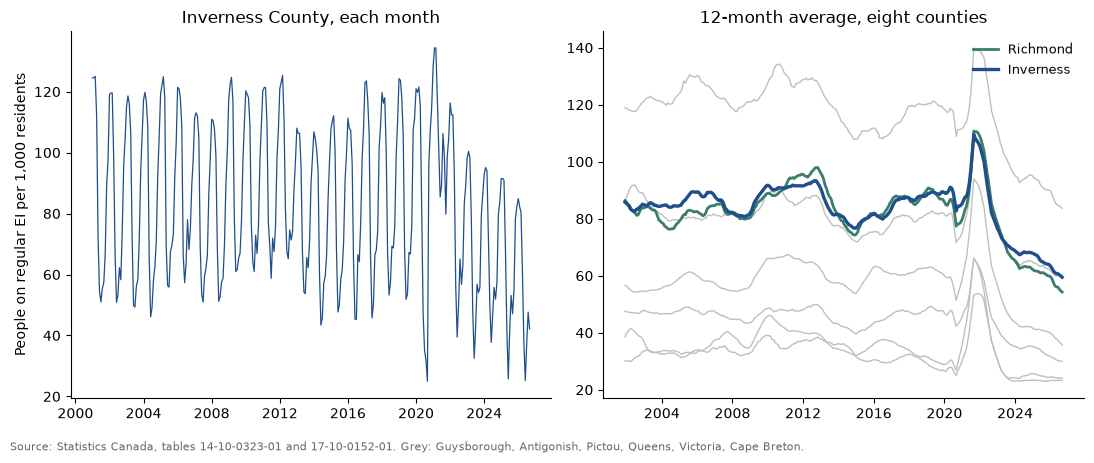

In [6]:
COUNTIES = {
    "1215": "Inverness",
    "1216": "Richmond",
    "1213": "Guysborough",
    "1214": "Antigonish",
    "1212": "Pictou",
    "1204": "Queens",
    "1218": "Victoria",
    "1217": "Cape Breton",
}


def by_county(product_id: int, other_dimensions: tuple, latest_n: int,
              first: str, last: str, periods: int) -> pd.DataFrame:
    members = statcan.geography_members(statcan.cube_metadata(product_id))
    members = members[members["code"].isin(COUNTIES)]
    members["coordinate"] = [statcan.coordinate(m, *other_dimensions) for m in members["member_id"]]
    assert set(members["code"]) == set(COUNTIES), "a county is missing from the table"
    data = statcan.fetch(product_id, list(members["coordinate"]), latest_n)
    data = window(data, members["coordinate"], first, last, periods)
    return data.merge(members[["coordinate", "code", "statcan_name"]], on="coordinate")


# Regular benefits (2), both sexes (1), 15 years and over (1); January 2001 onward.
ei = cached("ei_regular_cd_14100323.csv", lambda: by_county(14100323, (2, 1, 1), 480, EI_FIRST, EI_LAST, 309))
# Total, all genders (1), all ages (1).
cd_pop = cached("population_cd_17100152.csv", lambda: by_county(17100152, (1, 1), 40, POP_FIRST, POP_LAST, 25))

ei["month"] = pd.to_datetime(ei["ref_date"])
ei["year"] = ei["month"].dt.year
cd_pop["year"] = pd.to_datetime(cd_pop["ref_date"]).dt.year
ei = ei.merge(cd_pop[["code", "year", "value"]].rename(columns={"value": "population"}),
              on=["code", "year"], how="left", validate="many_to_one")
# 2026 has no population estimate yet: use the county's 2025 value. Any other gap is an error.
gaps = ei.loc[ei["population"].isna(), "year"]
assert set(gaps) <= {2026}, f"population missing for {sorted(set(gaps))}"
pop_2025 = cd_pop[cd_pop["year"] == 2025].set_index("code")["value"]
ei["population"] = ei["population"].fillna(ei["code"].map(pop_2025))
assert ei["population"].notna().all()
ei["per_1000"] = ei["value"] / ei["population"] * 1000
ei["county"] = ei["code"].map(COUNTIES)
print(len(ei), "rows;", ei["month"].min().date(), "to", ei["month"].max().date(),
      "| released:", ei["released"].max())

rate = ei.pivot(index="month", columns="county", values="per_1000")
assert rate.shape == (309, len(COUNTIES)) and not rate.isna().any().any()
smooth = rate.rolling(12).mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=False)
axes[0].plot(rate.index, rate["Inverness"], color="#1f4e8c", linewidth=0.9)
axes[0].set_title("Inverness County, each month")
axes[0].set_ylabel("People on regular EI per 1,000 residents")
for county in smooth.columns:
    if county not in ("Inverness", "Richmond"):
        axes[1].plot(smooth.index, smooth[county], color="0.75", linewidth=1)
axes[1].plot(smooth.index, smooth["Richmond"], color="#3a7d6b", linewidth=2, label="Richmond")
axes[1].plot(smooth.index, smooth["Inverness"], color="#1f4e8c", linewidth=2.4, label="Inverness")
axes[1].set_title("12-month average, eight counties")
axes[1].legend(frameon=False, fontsize=9)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, 0.01, "Source: Statistics Canada, tables 14-10-0323-01 and 17-10-0152-01. "
         "Grey: Guysborough, Antigonish, Pictou, Queens, Victoria, Cape Breton.",
         fontsize=8, color="0.4")
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig("fig-ei-by-county.png", dpi=160)
plt.show()

### How much of each county is the town?

In [7]:
share = pd.Series(
    {
        "Port Hawkesbury as a share of Inverness County, 2025":
            levels.loc[2025, "Port Hawkesbury"] / cd_pop.query("code == '1215' and year == 2025")["value"].iloc[0],
        "Richmond, Subd. A as a share of Richmond County, 2025":
            levels.loc[2025, "Richmond, Subd. A"] / cd_pop.query("code == '1216' and year == 2025")["value"].iloc[0],
    }
).mul(100).round(1)
share.to_frame("per cent")

,per cent
"Port Hawkesbury as a share of Inverness County, 2025",18.9
"Richmond, Subd. A as a share of Richmond County, 2025",42.9


## What these data cannot show

- **They cannot show an effect yet.** Every value here is from before the announcement,
  or (Employment Insurance, to September 2026) from before any construction.
- **Population is not income or jobs.** It moves slowly and answers only "did people stay or come?".
- **The town's population figures are estimates.** For a town of about 3,000, a change of
  a few dozen people can be estimation error. Values after 2021 will be revised.
- **The monthly series stops at the county.** A change in Inverness County cannot be
  assigned to Port Hawkesbury.
- **The comparison towns are not controls yet.** The list is a draft. No weights are fitted,
  and several towns had their own shocks (mill closures, mergers, other large projects).
- **Workers may not live in the town.** A job at the site can belong to a household in
  Richmond County, Antigonish or Cape Breton. Town-level data miss those households.